# Assignment 11: Spatial community composition — blobs or stripes?

### **This is an imaginary exercise.**

Maine can protect **1,000 km²** as two compact **blob** parks or two long,
narrow **stripe** parks. Each park covers 500 km². Which design would you
recommend for conserving amphibian diversity?

Follow the analyses in [Lab10](../labs/Lab10-CommunityComposition.ipynb), now
comparing park shapes. You may reuse its code and functions. Complete the code cells 
and short answers. Submit this notebook with its maps, tables, and saved summary CSVs.

## The data

[`ME_BlobStripeParks.geojson`](../data/ME_BlobStripeParks.geojson) contains two
roughly round blobs and two elliptical stripes, five times as long as they
are wide. All four are imaginary, nonoverlapping, and within Maine and the
source sample bounds. Each point already has a park assignment.

Sampling follows Lab10. All real records inside these parks are retained.
All source records in `amphibians.geojson` determine each observed species'
convex hull, its 50 km buffer, and its record-count weight. Each of **50 invented
species** inherits the buffered range and abundance weight of a randomly
sampled observed species. Added points are sampled within those ranges'
intersections with the parks, with counts proportional to the observed or
inherited weights. One point per invented species is reserved. There are
**1,500 total points**, including originals; seed = 597.

`synthetic` identifies generated points; `imaginary_species` identifies invented
taxa.

## 1. Import packages and load the data

Run from `docs/assignments` using the same environment as Lab10.

In [2]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.spatial.distance import jaccard, braycurtis

AREA_CRS = "EPSG:5070"
COLORS = {"blob": "forestgreen", "stripe": "darkorange"}
designs = ["blob", "stripe"]

In [3]:
features = gpd.read_file("../data/ME_BlobStripeParks.geojson")
parks = features[features.feature_type == "park"].copy()
parks = parks.to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)
park_order = list(parks.index)

display(parks[["park_name", "scenario", "area_km2"]])
print("Total occurrence records:", len(records))

,park_name,scenario,area_km2
park_id,,,
B1,Alder Crown Preserve,blob,500.0
B2,Hemlock Hollow Reserve,blob,500.0
S1,Fern Ribbon Preserve,stripe,500.0
S2,Silver Brook Reach,stripe,500.0


Total occurrence records: 1500


## 2. Map the parks and check the comparison

Map the four polygons and their points, using one color per design. Label the
park IDs. A simple map is enough.

Calculate area in km² and show the total area and number of occurrence records
for each design. Keep all records, including generated points and invented
species, in the analyses below.

scenario
blob      1000.000589
stripe    1000.000753
Name: measured_km2, dtype: float64

scenario
blob      845
stripe    655
Name: n_records, dtype: int64

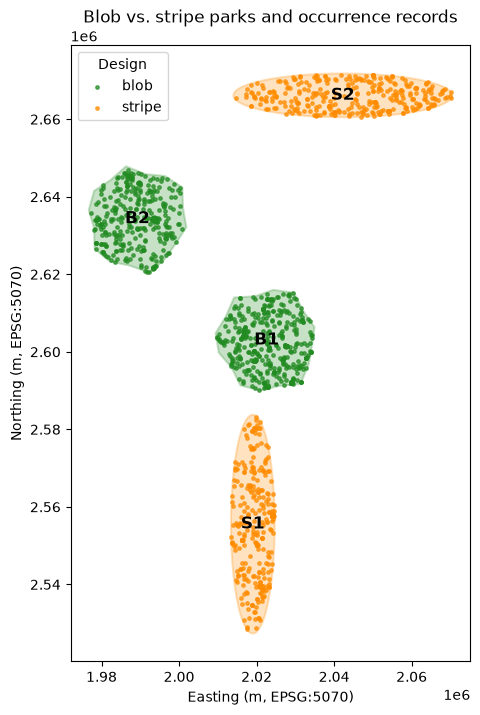

In [4]:
parks["measured_km2"] = parks.area / 1e6
display(parks.groupby("scenario").measured_km2.sum())

# Count records in each design with records.groupby("scenario").size().
# Plot the parks and occurrence points; label B1, B2, S1, and S2.

display(records.groupby("scenario").size().rename("n_records"))

fig, ax = plt.subplots(figsize=(8, 8))

for design in designs:
    color = COLORS[design]
    parks[parks.scenario == design].plot(
        ax=ax, facecolor=color, edgecolor=color, alpha=0.25, linewidth=1.5
    )
    records[records.scenario == design].plot(
        ax=ax, color=color, markersize=6, alpha=0.7, label=design
    )

# Label each park ID at its polygon centroid
for park_id, row in parks.iterrows():
    c = row.geometry.centroid
    ax.annotate(park_id, (c.x, c.y), ha="center", va="center",
                fontsize=12, fontweight="bold")

ax.set_title("Blob vs. stripe parks and occurrence records")
ax.set_xlabel("Easting (m, EPSG:5070)")
ax.set_ylabel("Northing (m, EPSG:5070)")
ax.legend(title="Design")
plt.show()

**Interpretation:** What is held equal between the designs? What differs besides
shape? Predict which design will capture more species, and explain why.

*Your answer:* Equal: The total area_km^2 is equal for both blob and stripe, 500 km^2 total for blob and 500 km^2 total for stripe. 
Differs: Blob total species occurrence is 845 and stripe total species occurence is 655. 
The long shape of the stripe park could allow more crossing into different species' range more easier as opposed to the circular blob shape which is more contained. However, the blob parks have more species occurrences than the stripe, but if they are more contained, it might be more difficult for the species to exchange alleles with other species outside the blob compared with the stripe parks. 

## 3. Build the community matrix

Rows are parks; columns are species; entries are record counts. A zero means
no records of that species in that park. It does not establish true absence.

In [5]:
community = pd.crosstab(records.park_id, records.species)
community = community.reindex(park_order, fill_value=0)
presence = community > 0

display(community)

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
B1,1,15,47,38,0,37,0,21,1,0,...,0,0,0,3,4,2,1,0,0,8
B2,1,17,39,21,0,26,3,11,5,0,...,0,0,1,5,5,8,0,1,1,5
S1,0,5,47,18,0,22,3,18,6,0,...,1,0,0,2,3,2,0,0,1,5
S2,1,7,11,19,1,13,0,11,4,1,...,0,1,0,3,10,5,1,1,0,8


In [6]:
n_species = community.shape[1]
print("Species in the whole dataset:", n_species)

Species in the whole dataset: 67


In [7]:
species_name = community.sum(axis=0).idxmax() 
print(species_name)
display(community[species_name])

Anaxyrus americanus


park_id
B1    47
B2    39
S1    47
S2    11
Name: Anaxyrus americanus, dtype: int64

How many species occur in the whole dataset? Choose one species and describe
its distribution among the four parks using its column in `community`.

*Your answer:* There are 67 different species in the whole dataset. I chose Anaxyrus americanus. In the blobs, it has 86 different occcurence records. In the stripes, it has 58 different occurrence records.

## 4. Richness, Shannon diversity, and evenness

Use the lab's function below. Shannon uses `scipy.stats.entropy`; larger values
reflect more species, greater evenness, or both.

In [8]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

In [9]:
# Calculate park_metrics = diversity(community).
# Add park names and scenarios from parks.
# Add evenness = np.exp(shannon) / richness, as in Lab10.
# Display the table and make a simple richness or Shannon plot.

park_metrics = diversity(community)
park_metrics["park_name"] = parks.loc[park_metrics.index, "park_name"]
park_metrics["scenario"] = parks.loc[park_metrics.index, "scenario"]
park_metrics["evenness"] = np.exp(park_metrics["shannon"]) / park_metrics["richness"]

display(park_metrics)

,n_records,richness,shannon,park_name,scenario,evenness
park_id,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136


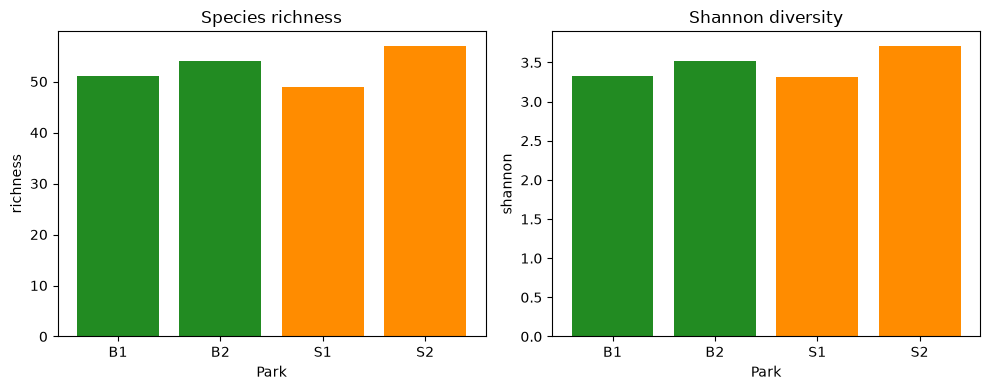

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, metric, title in zip(
    axes, ["richness", "shannon"], ["Species richness", "Shannon diversity"]
):
    ax.bar(
        park_metrics.index,
        park_metrics[metric],
        color=[COLORS[s] for s in park_metrics.scenario],
    )
    ax.set_title(title)
    ax.set_xlabel("Park")
    ax.set_ylabel(metric)

plt.tight_layout()
plt.show()

Does the richest park also have the highest Shannon diversity and evenness?
What would adding 100 records of an already common species do to these measures?

*Your answer:* Yes, S2 is the most species richness at 57. And it has both the highest Shannon diversity (3.7) and evenness 0.71. 
Richness: No change, since no new species are added, just the same ones. Shannon: Will decrease since there are more counts for the most common species. They take a larger share of the total record count and this causes the rare species to shrink. Evenness: It goes down, since Richness stays the same and Shannon falls. 


## 5. Alpha, beta, and gamma diversity

Pool the two blob parks, then the two stripe parks. For each design, calculate:

- **Alpha:** mean richness of its two parks.
- **Gamma:** richness in the pooled species list.
- **Multiplicative beta:** gamma divided by alpha.
- Total records and pooled Shannon diversity.

Keep the park rows in `community`; use `design_counts` for the pooled rows.

In [11]:
design_counts = pd.DataFrame(index=designs, columns=community.columns, dtype=float)
for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

# Use diversity(design_counts) to start design_metrics.
# Rename its richness column to gamma_richness.
# For each design, find its two rows in park_metrics.
# Calculate mean_park_alpha and beta_ratio, then display design_metrics.



In [12]:
design_metrics = diversity(design_counts)
design_metrics = design_metrics.rename(columns={"richness": "gamma_richness"})

In [13]:
design_metrics["mean_park_alpha"] = [
    park_metrics.loc[park_metrics.scenario == design, "richness"].mean()
    for design in design_metrics.index
]

In [14]:
design_metrics["beta_ratio"] = design_metrics["gamma_richness"] / design_metrics["mean_park_alpha"]
display(design_metrics)

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio
blob,845.0,60.0,3.460793,52.5,1.142857
stripe,655.0,63.0,3.606102,53.0,1.188679


Which design has higher gamma diversity? Does alpha or complementarity between
its two parks help explain the result? Why is pooled richness generally smaller
than the sum of the two park richnesses?

List species recorded only in blobs and species recorded only in stripes.
Hint: make a `set` from the species with positive counts in each pooled row;
subtract one set from the other.

*Your answer:*

Stripes has a higher gamma diversity to blob, 63>60. Complementarity mainly explains it, alpha is the same, beta would explain it. Summing park richness counts a species twice if they are in both parks, pooling counts the species once. So pooled richness equals the sum only if the two parks share no species at all, which is the case where beta = 2.

In [15]:
blob_species = set(design_counts.columns[design_counts.loc["blob"] > 0])
stripe_species = set(design_counts.columns[design_counts.loc["stripe"] > 0])

In [16]:
blob_only = sorted(blob_species - stripe_species)
print("Only in blobs:", len(blob_only))
print(blob_only)

Only in blobs: 4
['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']


In [17]:
stripe_only = sorted(stripe_species - blob_species)
print("Only in stripes:", len(stripe_only))
print(stripe_only)

Only in stripes: 7
['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']


In [18]:
# Make blob_species and stripe_species from design_counts.
# Print species unique to each design.

blob_species = set(design_counts.columns[design_counts.loc["blob"] > 0])
stripe_species = set(design_counts.columns[design_counts.loc["stripe"] > 0])

In [19]:
print("Only in blobs:", sorted(blob_species - stripe_species))
print("Only in stripes:", sorted(stripe_species - blob_species))

Only in blobs: ['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']
Only in stripes: ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']


### Jaccard dissimilarity

Jaccard compares presence/absence: 0 means identical species lists; 1 means no
shared species. Use `scipy.spatial.distance.jaccard` on rows of `presence`.

In [20]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))

# Build jaccard_distances, a four-by-four table, as in Lab10.
# Use nested loops over park_order and jaccard(presence.loc[a], presence.loc[b]).
# Display the table.


B1 versus B2: 0.25


In [21]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))

B1 versus B2: 0.25


In [22]:
jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)

for a in park_order:
    for b in park_order:
        jaccard_distances.loc[a, b] = jaccard(presence.loc[a], presence.loc[b])

In [23]:
display(jaccard_distances)

,B1,B2,S1,S2
B1,0.000000,0.250000,0.245614,0.200000
B2,0.250000,0.000000,0.283333,0.265625
S1,0.245614,0.283333,0.000000,0.317460
S2,0.200000,0.265625,0.317460,0.000000


Compare B1–B2 with S1–S2. Which design's two parks have more different species
lists? Does that agree with the beta ratios? Explain why Jaccard alone cannot
distinguish species replacement from differences in richness.

*Your answer:* The two stripe parks have more different species lists than the two blob parks, which is in alignment with the higher stripe beta ratio. Jaccard only counts how many species are in one park but not the other. 

### Bray–Curtis dissimilarity

Use `scipy.spatial.distance.braycurtis` on record counts. Make a second
four-by-four table, `bray_curtis_distances`.

Then repeat the B1–B2 and S1–S2 comparisons using **relative frequencies**:
divide each park's species counts by its total records before calling
`braycurtis`.

In [24]:
print("B1 versus B2:", braycurtis(community.loc["B1"], community.loc["B2"]))

# Build and display bray_curtis_distances using the Jaccard loop pattern.
# For each within-design pair, divide each row by its sum and compare again.

B1 versus B2: 0.19763313609467456


In [25]:
bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)

for a in park_order:
    for b in park_order:
        bray_curtis_distances.loc[a, b] = braycurtis(community.loc[a], community.loc[b])

In [26]:
display(bray_curtis_distances)

,B1,B2,S1,S2
B1,0.000000,0.197633,0.243455,0.326343
B2,0.197633,0.000000,0.248304,0.274457
S1,0.243455,0.248304,0.000000,0.303817
S2,0.326343,0.274457,0.303817,0.000000


In [27]:
relative = community.div(community.sum(axis=1), axis=0)

In [28]:
print("B1 versus B2 (counts):   ", braycurtis(community.loc["B1"], community.loc["B2"]))
print("B1 versus B2 (relative): ", braycurtis(relative.loc["B1"], relative.loc["B2"]))
print("S1 versus S2 (counts):   ", braycurtis(community.loc["S1"], community.loc["S2"]))
print("S1 versus S2 (relative): ", braycurtis(relative.loc["S1"], relative.loc["S2"]))

B1 versus B2 (counts):    0.19763313609467456
B1 versus B2 (relative):  0.19325497409210204
S1 versus S2 (counts):    0.30381679389312977
S1 versus S2 (relative):  0.3037032893264713


In [30]:
Do Jaccard and Bray–Curtis tell the same story? What information does Bray–Curtis
add? Why can unequal record totals affect its values, and what changes when
you use relative frequencies?

*Your answer:* Jaccard says that the most similar pair is B1-S2 at 0.20. And Curtis says B1-S2 is the most dissimilar pair at 0.326. Bray-Curtis adds abundance info. 
If one park has more records all the species will have higher counts there. There is only a small change with relative frequencies. 

SyntaxError: invalid character '–' (U+2013) (1642843326.py, line 1)

## 6. Compare equal numbers of records

Use record-based rarefaction to check whether the pooled richness comparison
persists when both designs contribute the same number of records. Draw without
replacement and repeat **300 times**, following the lab's loop.

For each design, report mean richness and the 2.5th and 97.5th percentiles of
the draws. These percentiles describe resampling variation, not confidence
intervals for true richness. Equal record counts do not establish equal survey
effort or detectability.

In [31]:
equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()

# For each design, select its records and start an empty richness_samples list.
# Repeat 300 times:
#     sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
#     Append sample.species.nunique() to richness_samples.
# Store records_drawn, mean_richness, q025, and q975 in rarefaction.
# Use np.mean and np.quantile, then display the table.

In [32]:
for design in designs:
    design_records = records[records.scenario == design]
    richness_samples = []

    for repeat in range(300):
        sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
        richness_samples.append(sample.species.nunique())

    rarefaction.loc[design, "records_drawn"] = equal_n
    rarefaction.loc[design, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[design, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[design, "q975"] = np.quantile(richness_samples, 0.975)

In [33]:
display(rarefaction)

,records_drawn,mean_richness,q025,q975
blob,655.0,57.423333,54.0,60.0
stripe,655.0,63.000000,63.0,63.0


Does equalizing record numbers change your preference? Which original sampling
biases and simulation assumptions remain?

*Your answer:* No, it makes it stronger. The records come from existing data which can be uneven in space, it's reflective of where people looked not necessarily how many species live there. Since 50 of the 67 are invented they copy the buffered convex hull range.

## 7. Rarity and restriction within the sample

Build `species_context` with each species' total records and number of occupied
parks. Define **record-rare** as at most five records across all four parks.
Use the same four parks as the reference throughout this section.

In [34]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)

,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Reuse `restriction_metrics` from Lab10 to calculate each park's:

- Sample-exclusive richness: species recorded in only one of the four parks.
- Weighted endemism proxy (WE): sum of `1 / parks_recorded` for species present.
- Corrected WE (CWE): WE divided by park richness.
- Record-rare richness: number of record-rare species present.

Compare the two designs' **pooled record-rare richness** as well: count each rare
species once per design, even if both parks record it.

In [35]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)

,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


In [36]:
print(len(rare_species))

24


In [37]:
design_counts = pd.DataFrame(index=designs, columns=community.columns, dtype=float)
for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

In [38]:
rare_by_design = {}

for design in designs:
    count = 0
    for species in rare_species:
        if design_counts.loc[design, species] > 0:
            count += 1
    rare_by_design[design] = count

print(rare_by_design)

{'blob': 17, 'stripe': 20}


In [44]:
# Copy the restriction_metrics function from Lab10.
# Calculate park_restriction = restriction_metrics(community).
# Display park_metrics.join(park_restriction).

# For each design, loop through rare_species.
# Count a species once if design_counts.loc[design, species] > 0.

def restriction_metrics(community_counts, rare=None):
    if rare is None:
        rare = rare_species

    presence_table = community_counts > 0
    parks_recorded = presence_table.sum(axis=0)

    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive_richness", "WE", "CWE", "record_rare_richness"],
        dtype=float,
    )

    for park, row in presence_table.iterrows():
        present = row[row].index
        richness = len(present)

        results.loc[park, "sample_exclusive_richness"] = (parks_recorded[present] == 1).sum()
        results.loc[park, "WE"] = (1 / parks_recorded[present]).sum()
        results.loc[park, "CWE"] = results.loc[park, "WE"] / richness if richness > 0 else np.nan
        results.loc[park, "record_rare_richness"] = len(set(present) & set(rare))

    return results

Does a park with high WE also have high CWE? Which design captures more
record-rare species? Are any sample-exclusive species relatively well recorded?
Explain why these results do not establish that a species is endemic to a park
or has a small population. How might invented species with few generated
records affect these metrics?

*Your answer:* No, not necessarily. Stripes captured more record-rare species 20 to 17. 

## 8. Save results and make a recommendation

Save `park_metrics.join(park_restriction)`, `design_metrics`, `species_context`,
`jaccard_distances`, `bray_curtis_distances`, and `rarefaction` as CSVs.

In [45]:
output_dir = Path("outputs/Assignment11")
output_dir.mkdir(parents=True, exist_ok=True)

# Save each table with .to_csv(output_dir / "table_name.csv").

In [49]:
park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")
design_metrics.to_csv(output_dir / "design_metrics.csv")
jaccard_distances.to_csv(output_dir / "jaccard_distances.csv")
bray_curtis_distances.to_csv(output_dir / "bray_curtis_distances.csv")
rarefaction.to_csv(output_dir / "rarefaction.csv")
species_context.to_csv(output_dir / "species_context.csv")

In [43]:
print(len(rare_species), design_counts.shape)

24 (2, 67)


In [47]:
park_restriction = restriction_metrics(community)
display(park_metrics.join(park_restriction))

,n_records,richness,shannon,park_name,scenario,evenness,sample_exclusive_richness,WE,CWE,record_rare_richness
park_id,,,,,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485,1.0,14.833333,0.290850,9.0
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327,3.0,17.666667,0.327160,13.0
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666,2.0,15.000000,0.306122,8.0
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136,4.0,19.500000,0.342105,17.0


In [48]:
park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")
design_metrics.to_csv(output_dir / "design_metrics.csv")
jaccard_distances.to_csv(output_dir / "jaccard_distances.csv")
bray_curtis_distances.to_csv(output_dir / "bray_curtis_distances.csv")
rarefaction.to_csv(output_dir / "rarefaction.csv")
species_context.to_csv(output_dir / "species_context.csv")

### Conservation recommendation (400–600 words)

Recommend blobs, stripes, or explain why the evidence does not favor one.
Support your conclusion with your map and numerical results. Address:

1. Alpha, gamma, beta, and the species contributed by each design.
2. Shannon diversity, evenness, Jaccard, and Bray–Curtis: which comparisons
   influence your decision, and why?
3. Whether rarefaction changes the result, and what rarity and restriction add.
4. Why these four locations cannot isolate a causal effect of shape. The sampler
   includes geographic ranges and reporting patterns, but no explicit edge
   effects, dispersal, or population persistence. What additional biological
   evidence or repeated park placements would help test your explanation?

*Your recommendation:*
1.) Both the blob and stripe parks have the same amount of area, 500 km^2 so since the area amount is the same, any differences in the number of species can't be explained by the size difference of the two types of parks. Both types of parks have similar alpha diversity, 52.5 for blobs and 53 for stripes, so both parks have very similar number of species. Stripes have higher gamma richness, 63 to 60 and a higher beta 1. So stripes have a little bit more different species than blobs. 

2.) Shannon diversity is bigger in stripes (pooled) compared to blobs, 3.61 to 3.46, S2 has the highest richness, evenness, and shannon diversity of the four parks. Jaccard supports the beta results, Bray-Curtis shows that B1 and S2 are the most different in abundance but they are most similar in species presence.
Shannon diversity influences the most since it combines both species richness and specie evenness. 

3.) Stripes beat blobs in both rarefaction and restriction.

4.) Location in this case, can't be isolated as a causal effect of park shape since the locations of these parks are spread out and not within a bigger isolated area. Since they are spread out, you can't control for certain factors such as range overlap. 

Overall, I think stripes is would beat blobs for conserving amphibian diversity. 
